<a href="https://colab.research.google.com/github/Abeni-style/GEREX-TigrinyaLens/blob/main/notebooks/TigrinyaLens_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TigrinyaLens: Testing English-to-Tigrinya Translation Quality

**Track:** AI + Languages  
**Starting point:** Section 4.4.2, Translation Quality Test  
**Model:** `facebook/nllb-200-distilled-600M`  
**Dataset:** `openlanguagedata/flores_plus`  
**Languages:** English → Tigrinya and English → French  
**Test sample:** 100 matching English sentences from `devtest`

## What the project does

TigrinyaLens compares translations of the same 100 English sentences into Tigrinya and French. It measures similarity to professional FLORES+ references using **chrF** (the primary metric) and **BLEU** (secondary metric). It also identifies five low-scoring examples per language and prepares a short human-review task for the three Tigrinya-speaking team members.

**Input:** an English sentence.  
**Output:** a machine-generated Tigrinya translation and a French translation, plus automatic evaluation scores across the test set.

**Intended user:** a Tigrinya-speaking secondary-school student in Tigray who receives school or educational information in English and wants to understand it in Tigrinya. The tool is an experimental prototype; it does not guarantee correct translations and must not be relied on for medical, legal, or other high-stakes decisions.

## Research rules

- This notebook uses a pretrained model for inference. It does not train or fine-tune NLLB.
- It uses the FLORES+ `devtest` split as held-out evaluation data.
- The same English sentence IDs are used for both target languages.
- The English-copy baseline is a negative control, not a competing translation model.
- A low chrF score is a prompt to inspect a sentence, not proof that the translation is wrong.
- Human ratings must be completed independently by all three team members. Never invent ratings or conclusions.

**Fresh Colab setup:** use a new Google Colab notebook, select a GPU if available, and run these cells from top to bottom. If a cell fails, stop at that cell and share the complete error; do not silently change the dataset or variable names.

## 1. Install the libraries

Run once in the new Colab runtime. Colab already provides PyTorch in most runtimes, so this cell does not reinstall it.

In [2]:
%pip -q install -U datasets transformers sentencepiece sacrebleu huggingface_hub pandas numpy matplotlib scipy gradio

## 2. Import libraries

In [3]:
import os
import json
import random
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import sacrebleu

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from IPython.display import display

print("Imports completed.")
print("PyTorch:", torch.__version__)
print("SacreBLEU:", sacrebleu.__version__)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Imports completed.
PyTorch: 2.14.1+cu130
SacreBLEU: 2.6.0


## 3. Hugging Face access (login is normally optional)

The FLORES+ dataset and NLLB-200 model are public Hugging Face resources, so authentication is normally not required. If a download returns an authorization error, sign in to Hugging Face through its secure login flow in the Colab session. Never paste an access token into a code cell, notebook output, chat, or public repository.

In [7]:
from huggingface_hub import notebook_login

notebook_login()

## 4. Set the experiment configuration

Only replace the team placeholders. The language codes and dataset/model identifiers are fixed for this experiment.

In [8]:
# Public project team details. Contact emails are intentionally omitted.
TEAM_NAME = "GEREX"
TEAM_MEMBERS = [
    {"name": "Amaniel Mebrahtom", "school": "Kallamino Special High School"},
    {"name": "Ambassador Girmay", "school": "Kallamino Special High School"},
    {"name": "Abenezer Shebabaw", "school": "Kallamino Special High School"},
]

# Dataset and model
DATASET_ID = "openlanguagedata/flores_plus"
MODEL_ID = "facebook/nllb-200-distilled-600M"

# NLLB language codes
SOURCE_LANG = "eng_Latn"
TIGRINYA_LANG = "tir_Ethi"
FRENCH_LANG = "fra_Latn"

# Experiment settings
SPLIT_NAME = "devtest"
NUMBER_OF_TEST_EXAMPLES = 100
NUMBER_OF_HUMAN_EVALUATION_EXAMPLES = 10
RANDOM_SEED = 42
BATCH_SIZE = 8
MAX_SOURCE_LENGTH = 256
MAX_NEW_TOKENS = 256
BEAM_SIZE = 4

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

OUTPUT_DIR = "/content/tigrinyalens_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project: TigrinyaLens")
print("Team:", TEAM_NAME)
print("Dataset:", DATASET_ID)
print("Model:", MODEL_ID)
print("Device:", DEVICE)
print("Test sentences:", NUMBER_OF_TEST_EXAMPLES)

Project: TigrinyaLens
Team: GEREX
Dataset: openlanguagedata/flores_plus
Model: facebook/nllb-200-distilled-600M
Device: cuda
Test sentences: 100


## 5. Load the three FLORES+ language configurations

Your actual FLORES+ repository output showed separate configurations named `eng_Latn`, `tir_Ethi`, and `fra_Latn`, rather than paired configuration names. Each language split uses the columns `id` and `text`. This cell follows that observed structure.

In [9]:
print("Loading English...")
english_data = load_dataset(DATASET_ID, SOURCE_LANG)

print("Loading Tigrinya...")
tigrinya_data = load_dataset(DATASET_ID, TIGRINYA_LANG)

print("Loading French...")
french_data = load_dataset(DATASET_ID, FRENCH_LANG)

for language, dataset_dict in [
    ("English", english_data),
    ("Tigrinya", tigrinya_data),
    ("French", french_data),
]:
    if SPLIT_NAME not in dataset_dict:
        raise ValueError(
            f"'{SPLIT_NAME}' split not found for {language}. "
            f"Available splits: {list(dataset_dict.keys())}"
        )

english_test = english_data[SPLIT_NAME]
tigrinya_test = tigrinya_data[SPLIT_NAME]
french_test = french_data[SPLIT_NAME]

for language, split in [
    ("English", english_test),
    ("Tigrinya", tigrinya_test),
    ("French", french_test),
]:
    if not {"id", "text"}.issubset(split.column_names):
        raise ValueError(
            f"Unexpected {language} columns: {split.column_names}. "
            "This notebook expects the observed FLORES+ schema: id and text."
        )

print("FLORES+ language datasets loaded.")
print("English rows:", len(english_test))
print("Tigrinya rows:", len(tigrinya_test))
print("French rows:", len(french_test))

Loading English...


Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

eng_Latn.jsonl:   0%|          | 0.00/423k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/440k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

... (12 outputs left out)

fra_Latn.jsonl:   0%|          | 0.00/472k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating devtest split: 0 examples [00:00, ? examples/s]

FLORES+ language datasets loaded.
English rows: 1012
Tigrinya rows: 1012
French rows: 1012


## 6. Align the languages and select 100 shared sentences

We align by sentence ID, not by assuming row order. The same selected IDs are used for English, Tigrinya, and French. The fixed random seed makes the sample reproducible.

In [10]:
def make_id_text_map(split, language_name):
    mapping = {}
    for row in split:
        sentence_id = str(row["id"])
        text = row["text"]
        if sentence_id in mapping:
            raise ValueError(f"Duplicate sentence ID in {language_name}: {sentence_id}")
        if not isinstance(text, str) or not text.strip():
            raise ValueError(f"Empty or invalid sentence in {language_name}: {sentence_id}")
        mapping[sentence_id] = text.strip()
    return mapping

english_map = make_id_text_map(english_test, "English")
tigrinya_map = make_id_text_map(tigrinya_test, "Tigrinya")
french_map = make_id_text_map(french_test, "French")

shared_ids = sorted(set(english_map) & set(tigrinya_map) & set(french_map))
if len(shared_ids) < NUMBER_OF_TEST_EXAMPLES:
    raise ValueError(
        f"Only {len(shared_ids)} sentence IDs are shared across the three languages; "
        f"{NUMBER_OF_TEST_EXAMPLES} are required."
    )

rng = random.Random(RANDOM_SEED)
example_ids = rng.sample(shared_ids, NUMBER_OF_TEST_EXAMPLES)

english_sentences = [english_map[sid] for sid in example_ids]
tigrinya_references = [tigrinya_map[sid] for sid in example_ids]
french_references = [french_map[sid] for sid in example_ids]

assert len(english_sentences) == NUMBER_OF_TEST_EXAMPLES
assert len(tigrinya_references) == NUMBER_OF_TEST_EXAMPLES
assert len(french_references) == NUMBER_OF_TEST_EXAMPLES

print("Paired data verified.")
print("English:", len(english_sentences))
print("Tigrinya references:", len(tigrinya_references))
print("French references:", len(french_references))
print("Example ID:", example_ids[0])
print("\nEnglish:", english_sentences[0])
print("Tigrinya reference:", tigrinya_references[0])
print("French reference:", french_references[0])

Paired data verified.
English: 100
Tigrinya references: 100
French references: 100
Example ID: 677

English: This provides us with a lot of information and material to build simulation models which help us to understand processes in our mind.
Tigrinya reference: እዚ አብ ኣእምሮና ምርዳእ ንክንክእል ዝሕግዘና ስቲሙሌሽን ንምህናፅ ዝሕግዝ ብዙሕ ሓበሬታን ኣቕሓን ንረኅበሉ ኢና።
French reference: Cela nous donne beaucoup d’informations et de matériel pour construire des modèles de simulation qui nous aident à comprendre les processus dans notre esprit.


## 7. Load NLLB-200

The model is used for inference only. The notebook checks that the model tokenizer recognizes all three language codes.

In [11]:
print("Loading NLLB tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    src_lang=SOURCE_LANG
)
tokenizer.src_lang = SOURCE_LANG

print("Loading NLLB model...")
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID)
model = model.to(DEVICE)
model.eval()

FRENCH_TOKEN_ID = tokenizer.convert_tokens_to_ids(FRENCH_LANG)
TIGRINYA_TOKEN_ID = tokenizer.convert_tokens_to_ids(TIGRINYA_LANG)

if FRENCH_TOKEN_ID == tokenizer.unk_token_id:
    raise ValueError("NLLB tokenizer does not recognize fra_Latn.")
if TIGRINYA_TOKEN_ID == tokenizer.unk_token_id:
    raise ValueError("NLLB tokenizer does not recognize tir_Ethi.")

print("Model loaded on:", DEVICE)
print("French token ID:", FRENCH_TOKEN_ID)
print("Tigrinya token ID:", TIGRINYA_TOKEN_ID)

Loading NLLB tokenizer...


config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Model loaded on: cuda
French token ID: 256057
Tigrinya token ID: 256176


## 8. Define one translation function

Greedy decoding (`num_beams=1`) and beam search (`num_beams=4`) are two decoding strategies for the same model, not two different models. We use deterministic decoding so repeated runs with the same setup are comparable.

In [12]:
def translate_batch(texts, target_language, num_beams=1):
    if target_language not in [TIGRINYA_LANG, FRENCH_LANG]:
        raise ValueError(f"Unsupported target language: {target_language}")
    if not texts:
        return []

    tokenizer.src_lang = SOURCE_LANG
    target_token_id = tokenizer.convert_tokens_to_ids(target_language)

    encoded = tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_SOURCE_LENGTH,
    )
    encoded = {key: value.to(DEVICE) for key, value in encoded.items()}

    with torch.inference_mode():
        generated = model.generate(
            **encoded,
            forced_bos_token_id=target_token_id,
            num_beams=num_beams,
            do_sample=False,
            max_new_tokens=MAX_NEW_TOKENS,
        )

    return tokenizer.batch_decode(generated, skip_special_tokens=True)

# Test both target languages before processing all 100 examples.
print("Tigrinya test:", translate_batch([english_sentences[0]], TIGRINYA_LANG, BEAM_SIZE)[0])
print("French test:", translate_batch([english_sentences[0]], FRENCH_LANG, BEAM_SIZE)[0])

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Tigrinya test: እዚ ድማ ነቲ ኣብ ኣእምሮና ዘሎ መስርሕ ንኽንርድኦ ዝሕግዘና ሞዴላት ምስምሳል ንምፍጣር ብዙሕ ሓበሬታን ቁሳቁስን ይህበና።
French test: Cela nous fournit beaucoup d'informations et de matériel pour construire des modèles de simulation qui nous aident à comprendre les processus dans notre esprit.


## 9. Generate the translations

This creates four output lists: French greedy, French beam-4, Tigrinya greedy, and Tigrinya beam-4.

In [13]:
tigrinya_greedy = []
tigrinya_beam = []
french_greedy = []
french_beam = []

for start in range(0, len(english_sentences), BATCH_SIZE):
    batch = english_sentences[start:start + BATCH_SIZE]

    tigrinya_greedy.extend(translate_batch(batch, TIGRINYA_LANG, num_beams=1))
    tigrinya_beam.extend(translate_batch(batch, TIGRINYA_LANG, num_beams=BEAM_SIZE))
    french_greedy.extend(translate_batch(batch, FRENCH_LANG, num_beams=1))
    french_beam.extend(translate_batch(batch, FRENCH_LANG, num_beams=BEAM_SIZE))

    print(f"Translated {min(start + BATCH_SIZE, len(english_sentences))}/{len(english_sentences)} source sentences")

for name, outputs in [
    ("Tigrinya greedy", tigrinya_greedy),
    ("Tigrinya beam", tigrinya_beam),
    ("French greedy", french_greedy),
    ("French beam", french_beam),
]:
    if len(outputs) != NUMBER_OF_TEST_EXAMPLES:
        raise RuntimeError(f"Unexpected output count for {name}: {len(outputs)}")

print("All translation runs completed.")

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Translated 8/100 source sentences


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Translated 16/100 source sentences


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Translated 24/100 source sentences


... (16 outputs left out)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Translated 96/100 source sentences


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Translated 100/100 source sentences
All translation runs completed.


## 10. Inspect sample translations

Check that the outputs are in the intended languages and contain text. Fluency must still be checked by people; a non-empty output is not proof of correctness.

In [14]:
sample_table = pd.DataFrame({
    "English": english_sentences[:5],
    "Tigrinya model": tigrinya_beam[:5],
    "Tigrinya reference": tigrinya_references[:5],
    "French model": french_beam[:5],
    "French reference": french_references[:5],
})
display(sample_table)

,English,Tigrinya model,Tigrinya reference,French model,French reference
0,This provides us with a lot of information and...,እዚ ድማ ነቲ ኣብ ኣእምሮና ዘሎ መስርሕ ንኽንርድኦ ዝሕግዘና ሞዴላት ምስ...,እዚ አብ ኣእምሮና ምርዳእ ንክንክእል ዝሕግዘና ስቲሙሌሽን ንምህናፅ ዝሕግ...,Cela nous fournit beaucoup d'informations et d...,Cela nous donne beaucoup d’informations et de ...
1,"As a result, the performers smoke cannabis joi...",ከም ውጽኢቱ ድማ እቶም ተዋሳእቲ ኣብ መድረኽ ሓመድ ካናቢስ ይጨውዩ፣ እቲ...,ከም ውጽኢቱ እቶም ተዋሳእቲ ካናቢስ ኣብ መድረኽ ወጺዮም የትክኹ ነበሩ፣ ...,"En conséquence, les artistes fument des joints...","En conséquence, les artistes fument des joints..."
2,"One antibody cocktail, ZMapp, initially showed...",ሓደ ጸረ ኣካላት ኮክቴል፡ ZMapp፡ ኣብ ፈለማ ኣብ ሜዳ ተስፋ ዝህብ እ...,ሓደ ዜድማፕ ዝተብሃለ ኣንቲባዲ ንጥረነገር፣ ኣብ መጀመርታ ኣብቲ ዘፈር ተ...,"Un cocktail d'anticorps, ZMapp, a d'abord mont...",Même si l'administration d'un cocktail d'antic...
3,"All the ships were sunk, except for one Britis...",ብዘይካ ሓንቲ ብሪጣንያ እትርከብ ጃልባ፡ ኵለን ጃልባታት ዕንባባ፡ ዳርጋ ...,ብዘይካ ሓንቲ ናይ እንግሊዝ መርከብ፣ ኩለን መርከባት ጥሒለን። ናብ 200...,"Tous les navires ont été coulés, à l'exception...","Tous les navires furent coulés, à l’exception ..."
4,Researchers from Princeton University in the U...,ተመራመርቲ ዩኒቨርሲቲ ፕሪንስተን ኣብ ሕቡራት መንግስታት ኣመሪካን ዩኒቨር...,ተመራመርቲ ካብ ዩኒቨርስቲ ፕሪንስተን ኣሜሪካን ኡፕሳላ ዩኒቨርስቲ ስዊድን...,Des chercheurs de l'Université de Princeton au...,Des chercheurs de l'université de Princeton au...


## 11. Normalize the text

This applies Unicode NFC normalization and trims repeated whitespace. It does not alter sentence meaning or repair translation errors.

In [15]:
def normalize_text(text):
    return " ".join(__import__("unicodedata").normalize("NFC", str(text)).split())

english_norm = [normalize_text(x) for x in english_sentences]
tigrinya_ref_norm = [normalize_text(x) for x in tigrinya_references]
french_ref_norm = [normalize_text(x) for x in french_references]
tigrinya_greedy_norm = [normalize_text(x) for x in tigrinya_greedy]
tigrinya_beam_norm = [normalize_text(x) for x in tigrinya_beam]
french_greedy_norm = [normalize_text(x) for x in french_greedy]
french_beam_norm = [normalize_text(x) for x in french_beam]

print("Normalization completed.")

Normalization completed.


## 12. Calculate chrF and BLEU

chrF is the primary metric requested by the hackathon brief. BLEU is reported as a secondary metric. These are similarity metrics, not percentages of translation accuracy.

In [16]:
def calculate_metrics(predictions, references):
    if len(predictions) != len(references):
        raise ValueError("Prediction and reference lengths do not match.")
    return {
        "chrF": sacrebleu.corpus_chrf(predictions, [references]).score,
        "BLEU": sacrebleu.corpus_bleu(predictions, [references]).score,
    }

metric_rows = []
conditions = [
    ("Tigrinya", "Greedy decoding", tigrinya_greedy_norm, tigrinya_ref_norm),
    ("Tigrinya", "Beam search (4 beams)", tigrinya_beam_norm, tigrinya_ref_norm),
    ("French", "Greedy decoding", french_greedy_norm, french_ref_norm),
    ("French", "Beam search (4 beams)", french_beam_norm, french_ref_norm),
]

for language, method, predictions, references in conditions:
    scores = calculate_metrics(predictions, references)
    metric_rows.append({
        "Language": language,
        "Method": method,
        "Examples": len(references),
        "chrF": scores["chrF"],
        "BLEU": scores["BLEU"],
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(2))

,Language,Method,Examples,chrF,BLEU
0,Tigrinya,Greedy decoding,100,23.61,3.03
1,Tigrinya,Beam search (4 beams),100,25.17,3.98
2,French,Greedy decoding,100,67.56,45.39
3,French,Beam search (4 beams),100,68.97,47.00


## 13. Compare against a simple copy-source negative control

This baseline returns the English input unchanged and scores it against the French or Tigrinya reference. It shows the result of not translating at all. It is a deliberately weak negative control, not a competing translation system.

In [17]:
copy_baseline_tigrinya = calculate_metrics(english_norm, tigrinya_ref_norm)
copy_baseline_french = calculate_metrics(english_norm, french_ref_norm)

baseline_df = pd.DataFrame([
    {"Language": "Tigrinya", "Method": "English-copy negative control", **copy_baseline_tigrinya},
    {"Language": "French", "Method": "English-copy negative control", **copy_baseline_french},
])

all_metrics = pd.concat([baseline_df, metrics_df], ignore_index=True)
print("All language and method results:")
display(all_metrics.round(2))

All language and method results:


,Language,Method,chrF,BLEU,Examples
0,Tigrinya,English-copy negative control,0.66,0.27,NaN
1,French,English-copy negative control,25.90,1.67,NaN
2,Tigrinya,Greedy decoding,23.61,3.03,100.0
3,Tigrinya,Beam search (4 beams),25.17,3.98,100.0
4,French,Greedy decoding,67.56,45.39,100.0
5,French,Beam search (4 beams),68.97,47.00,100.0


## 14. Identify the five lowest-scoring translations in each language

We rank beam-search outputs by sentence-level chrF. These are **low-scoring candidates for manual inspection**, not automatically proven translation errors. A valid alternative translation can have low overlap with a single reference.

In [18]:
def make_sentence_analysis(language, sources, hypotheses, references, ids):
    rows = []
    for sentence_id, source, hypothesis, reference in zip(ids, sources, hypotheses, references):
        sentence_chrf = sacrebleu.sentence_chrf(hypothesis, [reference]).score
        sentence_bleu = sacrebleu.sentence_bleu(hypothesis, [reference]).score
        rows.append({
            "example_id": sentence_id,
            "language": language,
            "English": source,
            "Model output": hypothesis,
            "Professional reference": reference,
            "sentence_chrF": sentence_chrf,
            "sentence_BLEU": sentence_bleu,
            "verified_error_category": "",
            "team_explanation": "",
        })
    return pd.DataFrame(rows)

tigrinya_analysis = make_sentence_analysis(
    "Tigrinya", english_norm, tigrinya_beam_norm, tigrinya_ref_norm, example_ids
)
french_analysis = make_sentence_analysis(
    "French", english_norm, french_beam_norm, french_ref_norm, example_ids
)

tigrinya_worst5 = tigrinya_analysis.nsmallest(5, "sentence_chrF").reset_index(drop=True)
french_worst5 = french_analysis.nsmallest(5, "sentence_chrF").reset_index(drop=True)

print("Five lowest-scoring Tigrinya examples:")
display(tigrinya_worst5)
print("Five lowest-scoring French examples:")
display(french_worst5)

Five lowest-scoring Tigrinya examples:


,example_id,language,English,Model output,Professional reference,sentence_chrF,sentence_BLEU,verified_error_category,team_explanation
0,687,Tigrinya,Blogs can also help improve student writing. W...,ብሉጻት ብሉጻት ብሉጻት ብሉጻት ብሉጻት ብሉጻት ብሉጻት ብሉጻት ብሉጻት ብ...,ብሎጋት ከምኡውን ናይ ተማሃሮ ናይ ምጽሓፍ ክእለት ንምምሕያሽ ክሕግዙ ይኽ...,1.056524,0.000000,,
1,358,Tigrinya,"It has brought us the train, the car, and many...",ኣብ ናይ የሆዋ መሰኻኽር እተገብረ ምብጻሕ,ባቡርን ማኪናን ካልእ ብዙሕ መጓዓዝያን እውን ኣምጺኡልና እዩ ።,4.474273,0.000000,,
2,833,Tigrinya,"Fruit pastries are common, with apples cooked ...",ኣብ ሓጋይ፡ ኣፕል ኣብ ሓጋይ፡ ቸሪን ፕላውን ኣብ ሓጋይ ይርኣዩ፣ ኣብ ም...,ቱፋሕ ዓመት ሙሉእ ምስ ቅጫ ተሓዊሱ ምስርሑ፣ቼሪታትን ፕላማትን ከዓ ኣብ ...,7.827883,2.407486,,
3,173,Tigrinya,Widespread looting reportedly continued overni...,ኣብ ጎደናታት ቢሽኬክ ሓለፍቲ ህግደፍ ስለዘይነበሩ ሰፊሕ ስርቂ ብለይቲ ተ...,እናተስፋሕፈሐ ዝርከብ ስርቒ ሕዚ እዋን አብ እዋን ለይቲ ፖሊስ አብ ዘየብ...,9.250743,0.000000,,
4,160,Tigrinya,"""They are cooler than the surrounding surface ...","""መዓልቲ ኻብቲ ኣብ ከባቢኣ ዘሎ ጠፈር ቀሊል፡ ምሸት ድማ ሞቕቲ እዩ።",ብቀትሪ ካብ ከባቢኦም ዝርከብ ላዕለዋይ ሰፈር ዝዝሕሉ ኮይኖም፣ ብምሸቱ ድ...,9.858679,3.386499,,


Five lowest-scoring French examples:


,example_id,language,English,Model output,Professional reference,sentence_chrF,sentence_BLEU,verified_error_category,team_explanation
0,658,French,"Generally speaking, two behaviors can emerge a...","En général, deux comportements peuvent apparaî...","De manière générale, deux comportements peuven...",31.563836,4.668191,,
1,857,French,Europe is a continent that is relatively small...,"L'Europe est un continent relativement petit, ...","L'Europe est un continent relativement petit, ...",33.813373,10.590558,,
2,644,French,"Sadly, as newer methods of writing have emerge...","Malheureusement, à mesure que de nouvelles mét...","Malheureusement, l'apparition de nouveaux mode...",37.847652,8.848967,,
3,172,French,The show originally featured amateur voice act...,L'émission contenait à l'origine des acteurs v...,"À l'origine, l'émission mettait en scène des c...",43.875488,16.102643,,
4,293,French,Israel demands an ongoing military presence in...,Israël exige une présence militaire continue d...,Israël exige une présence militaire permanente...,46.574948,17.710118,,


## 15. Prepare a short, blinded human-evaluation task

The three team members independently rate the **same 10 NLLB-200 Tigrinya model outputs** (the beam-search outputs). They do **not** rate the FLORES+ reference. They judge the model output against the English source. The professional FLORES+ reference and automatic chrF score are deliberately hidden from the raters to avoid influencing their judgments. After all ratings are submitted, the notebook joins the ratings to the reference and chrF for analysis.

Rate each NLLB Tigrinya output from 1 to 5 for:
- **Meaning:** Does the Tigrinya output preserve the English meaning?
- **Fluency:** Does it sound natural and understandable in Tigrinya?
- **Grammar:** Is the Tigrinya grammatically acceptable?

Use an error category if relevant: `no_obvious_error`, `incorrect_meaning`, `omission`, `grammar`, `names_numbers`, `unnatural_wording`, or `other`. Rate independently. Do not discuss scores until all three files are complete.

In [19]:
from google.colab import files

# Select the same reproducible 10 Tigrinya beam-search outputs for all raters.
human_rng = random.Random(RANDOM_SEED + 1)
human_positions = sorted(
    human_rng.sample(
        range(NUMBER_OF_TEST_EXAMPLES),
        NUMBER_OF_HUMAN_EVALUATION_EXAMPLES
    )
)

# Keep reference and chrF internally for analysis AFTER ratings are completed.
human_base = pd.DataFrame({
    "example_id": [str(example_ids[i]) for i in human_positions],
    "English": [english_sentences[i] for i in human_positions],
    "Tigrinya model output": [tigrinya_beam[i] for i in human_positions],
    "FLORES+ reference (hidden from raters)": [tigrinya_references[i] for i in human_positions],
    "sentence_chrF (hidden from raters)": [
        tigrinya_analysis.iloc[i]["sentence_chrF"] for i in human_positions
    ],
})

# Raters receive only the English source and the NLLB model output.
rater_template = human_base[[
    "example_id",
    "English",
    "Tigrinya model output"
]].copy()

RATER_FILES = ["rater_1.csv", "rater_2.csv", "rater_3.csv"]

for filename in RATER_FILES:
    sheet = rater_template.copy()
    sheet["Meaning (1-5)"] = ""
    sheet["Fluency (1-5)"] = ""
    sheet["Grammar (1-5)"] = ""
    sheet["Error category"] = ""
    sheet["Comment"] = ""
    sheet.to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False,
        encoding="utf-8-sig"
    )

instructions = """TIGRINYALENS — SHORT, BLINDED HUMAN EVALUATION

WHAT TO RATE: Rate the Tigrinya MODEL OUTPUT produced by NLLB-200 (beam search). Do NOT rate the FLORES+ reference. The reference and automatic chrF score are intentionally not included in your file.

Read the English source, then judge whether the Tigrinya model output preserves its meaning and is natural and grammatical. Different valid wording is acceptable.

Complete the same 10 examples independently. Do not discuss ratings with the other evaluators until all three files are complete.

Use whole-number scores from 1 to 5:
Meaning: 1 = meaning mostly wrong or missing; 3 = partly correct; 5 = meaning faithfully preserved.
Fluency: 1 = difficult to understand; 3 = understandable but unnatural; 5 = natural and clear.
Grammar: 1 = serious grammatical problems; 3 = noticeable problems; 5 = grammatical and clear.

Error categories: no_obvious_error, incorrect_meaning, omission, grammar, names_numbers, unnatural_wording, other.
Add a short comment when it helps explain a problem. Do not edit example_id, English, or Tigrinya model output. Save your completed file with its original filename.
"""

with open(
    os.path.join(OUTPUT_DIR, "human_evaluation_instructions.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(instructions)

# Download the three blank, separate rating sheets and instructions.
template_zip = os.path.join(OUTPUT_DIR, "human_evaluation_templates.zip")
with zipfile.ZipFile(template_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in RATER_FILES:
        z.write(os.path.join(OUTPUT_DIR, filename), arcname=filename)
    z.write(
        os.path.join(OUTPUT_DIR, "human_evaluation_instructions.txt"),
        arcname="human_evaluation_instructions.txt"
    )

print("Created three independent, blinded evaluation sheets.")
print("Raters evaluate NLLB Tigrinya model output, NOT the FLORES+ reference.")
files.download(template_zip)

Created three independent, blinded evaluation sheets.
Raters evaluate NLLB Tigrinya model output, NOT the FLORES+ reference.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Optional: upload the three completed human-evaluation files

If the three evaluators have already completed their independent rating sheets, upload `rater_1.csv`, `rater_2.csv`, and `rater_3.csv` here to recalculate the human-review summary. If you do not have the completed files during this run, cancel/skip the upload dialog. The notebook will continue with automatic evaluation and clearly mark the human re-analysis as not performed. Do not fill in ratings on behalf of the evaluators.

In [20]:
HUMAN_EVALUATION_COMPLETED = False
uploaded = files.upload()
missing = set(RATER_FILES) - set(uploaded.keys())
if missing:
    print("Human-rating re-analysis skipped for this run.")
    print("Missing files:", ", ".join(sorted(missing)))
    print("Automatic evaluation and report generation can continue.")
else:
    HUMAN_EVALUATION_COMPLETED = True
    print("All three completed rating files uploaded.")

Saving rater_1.csv to rater_1.csv
Saving rater_2.csv to rater_2.csv
Saving rater_3.csv to rater_3.csv
All three completed rating files uploaded.


## 17. Validate and summarize human ratings (only when all three files are available)

This cell checks that each evaluator scored the same 10 example IDs and entered whole-number ratings from 1 to 5. It calculates mean ratings and exploratory Spearman correlations with sentence-level chrF. With only 10 examples and three team evaluators, interpret the correlation cautiously.

In [22]:
from scipy.stats import spearmanr

expected_ids = set(human_base["example_id"].astype(str).str.strip())
rating_columns = ["Meaning (1-5)", "Fluency (1-5)", "Grammar (1-5)"]
all_ratings = []

for rater_number, filename in enumerate(RATER_FILES, start=1):
    df = pd.read_csv(filename, dtype={"example_id": str})
    df.columns = [c.strip() for c in df.columns]
    df["example_id"] = df["example_id"].astype(str).str.strip()

    # Ensure Comment and Error category columns exist even if left blank
    if "Comment" not in df.columns:
        df["Comment"] = ""
    else:
        df["Comment"] = df["Comment"].fillna("")

    if "Error category" not in df.columns:
        df["Error category"] = "no_obvious_error"
    else:
        df["Error category"] = df["Error category"].fillna("").astype(str).str.strip()

    required = {"example_id", *rating_columns, "Error category", "Comment"}
    if not required.issubset(df.columns):
        raise ValueError(
            f"{filename} is missing columns: {sorted(required - set(df.columns))}"
        )

    if df["example_id"].duplicated().any() or set(df["example_id"]) != expected_ids:
        raise ValueError(
            f"Example IDs in {filename} do not match the human-evaluation sample."
        )

    for column in rating_columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")
        if df[column].isna().any() or not df[column].between(1, 5).all():
            raise ValueError(
                f"{filename}: {column} must contain complete ratings from 1 to 5."
            )
        if not np.equal(df[column], np.floor(df[column])).all():
            raise ValueError(
                f"{filename}: {column} must contain whole-number ratings."
            )

    df["Rater"] = f"Rater {rater_number}"
    all_ratings.append(df)

ratings_long = pd.concat(all_ratings, ignore_index=True)

ratings_summary = (
    ratings_long.groupby("example_id")[rating_columns]
    .mean()
    .reset_index()
)
ratings_summary["Mean human rating"] = ratings_summary[rating_columns].mean(axis=1)

# Reveal/attach the professional reference and chrF only AFTER blind ratings are complete.
human_base["example_id"] = human_base["example_id"].astype(str).str.strip()
human_analysis = human_base.merge(
    ratings_summary,
    on="example_id",
    validate="one_to_one"
)

human_analysis["sentence_chrF"] = pd.to_numeric(
    human_analysis["sentence_chrF (hidden from raters)"],
    errors="raise"
)

correlations = []
for column in rating_columns + ["Mean human rating"]:
    if (
        human_analysis[column].nunique() < 2
        or human_analysis["sentence_chrF"].nunique() < 2
    ):
        rho, p_value = np.nan, np.nan
    else:
        correlation = spearmanr(
            human_analysis["sentence_chrF"],
            human_analysis[column]
        )
        rho = float(correlation.statistic)
        p_value = float(correlation.pvalue)

    correlations.append({
        "Human rating dimension": column,
        "Spearman rho": rho,
        "p-value": p_value,
        "n": len(human_analysis),
    })

correlation_df = pd.DataFrame(correlations)

# Summarize error categories selected by raters
error_counts_df = (
    ratings_long["Error category"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .rename_axis("Error category")
    .reset_index(name="Count")
)

print("Average human ratings:")
display(
    human_analysis[rating_columns + ["Mean human rating"]]
    .mean()
    .to_frame("Average score")
    .round(2)
)

print("\nExploratory correlation with sentence-level chrF:")
display(correlation_df.round(3))

print("\nError categories reported across all 3 raters:")
display(error_counts_df)

ratings_long.to_csv(
    os.path.join(OUTPUT_DIR, "human_ratings_all.csv"),
    index=False,
    encoding="utf-8-sig")
human_analysis.to_csv(
    os.path.join(OUTPUT_DIR, "human_ratings_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)
correlation_df.to_csv(
    os.path.join(OUTPUT_DIR, "human_chrf_correlation.csv"),
    index=False,
    encoding="utf-8-sig"
)
error_counts_df.to_csv(
    os.path.join(OUTPUT_DIR, "human_error_categories.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nHuman evaluation analysis completed successfully!")

Average human ratings:


/tmp/ipykernel_1394/3063813038.py:16: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["Comment"] = df["Comment"].fillna("")
/tmp/ipykernel_1394/3063813038.py:16: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["Comment"] = df["Comment"].fillna("")
/tmp/ipykernel_1394/3063813038.py:16: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["Comment"] = df["Comment"].fillna("")


,Average score
Meaning (1-5),2.47
Fluency (1-5),2.27
Grammar (1-5),2.77
Mean human rating,2.50



Exploratory correlation with sentence-level chrF:


,Human rating dimension,Spearman rho,p-value,n
0,Meaning (1-5),0.747,0.013,10
1,Fluency (1-5),0.684,0.029,10
2,Grammar (1-5),0.434,0.210,10
3,Mean human rating,0.732,0.016,10



Error categories reported across all 3 raters:


,Error category,Count
0,addition and mistranslation,2
1,"Mistranslation, omission, addition, terminology",2
2,grammatical error,2
3,mistranslation and fragmented,2
4,mistranslation,2
5,mistranslation and addition,2
6,addition,2
7,omission,1
8,"addition, punctuation error",1
9,fluency,1



Human evaluation analysis completed successfully!


## 18. Save metrics, charts, metadata, and a write-up draft

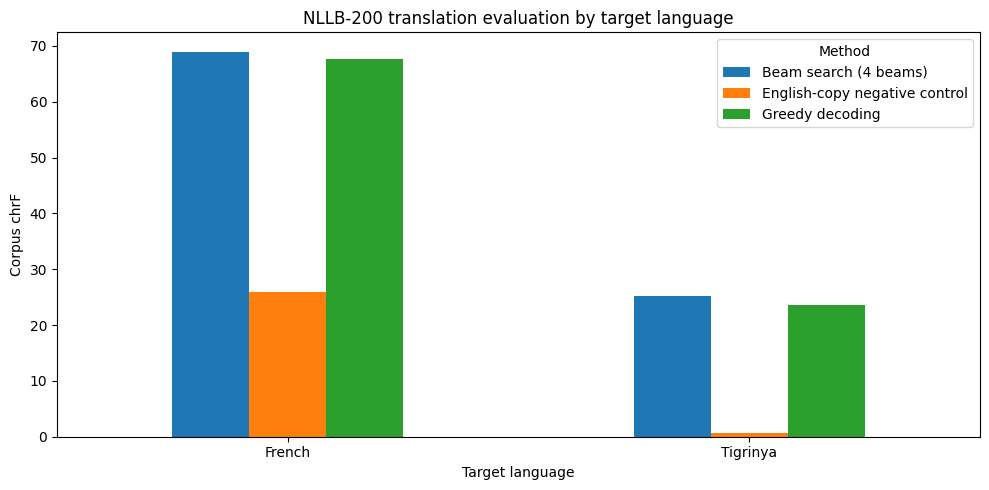

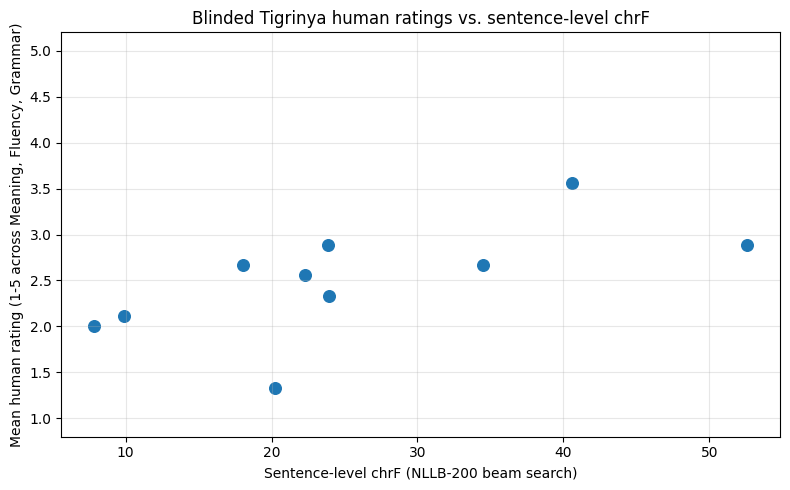

Core results, charts, metadata, and completed write-up saved in: /content/tigrinyalens_outputs


In [24]:
from importlib.metadata import version as pkg_version

PROJECT_TITLE = "TigrinyaLens: Testing English-to-Tigrinya Translation Quality"

# Ensure Examples column is filled for all rows in all_metrics
all_metrics["Examples"] = all_metrics["Examples"].fillna(NUMBER_OF_TEST_EXAMPLES).astype(int)

# Save automatic metrics and comparison table.
metrics_path = os.path.join(OUTPUT_DIR, "translation_metrics.csv")
all_metrics_path = os.path.join(OUTPUT_DIR, "translation_metrics_with_baseline.csv")
metrics_df.to_csv(metrics_path, index=False)
all_metrics.to_csv(all_metrics_path, index=False)

# Save sentence-level data and worst examples.
results_df = pd.DataFrame({
    "example_id": example_ids,
    "English": english_sentences,
    "Tigrinya reference": tigrinya_references,
    "Tigrinya greedy": tigrinya_greedy,
    "Tigrinya beam": tigrinya_beam,
    "French reference": french_references,
    "French greedy": french_greedy,
    "French beam": french_beam,
})
results_df.to_csv(os.path.join(OUTPUT_DIR, "all_translations.csv"), index=False, encoding="utf-8-sig")
tigrinya_worst5.to_csv(os.path.join(OUTPUT_DIR, "tigrinya_five_lowest_chrf.csv"), index=False, encoding="utf-8-sig")
french_worst5.to_csv(os.path.join(OUTPUT_DIR, "french_five_lowest_chrf.csv"), index=False, encoding="utf-8-sig")

# Automatic chrF chart.
chart_path = os.path.join(OUTPUT_DIR, "chrf_comparison.png")
chart_data = all_metrics.pivot(index="Language", columns="Method", values="chrF")
ax = chart_data.plot(kind="bar", figsize=(10, 5))
ax.set_title("NLLB-200 translation evaluation by target language")
ax.set_ylabel("Corpus chrF")
ax.set_xlabel("Target language")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

# Scatter plot: Human ratings vs. sentence-level chrF
human_chart_path = os.path.join(OUTPUT_DIR, "human_rating_vs_chrf.png")
fig, ax2 = plt.subplots(figsize=(8, 5))
ax2.scatter(human_analysis["sentence_chrF"], human_analysis["Mean human rating"], s=70)
ax2.set_title("Blinded Tigrinya human ratings vs. sentence-level chrF")
ax2.set_xlabel("Sentence-level chrF (NLLB-200 beam search)")
ax2.set_ylabel("Mean human rating (1-5 across Meaning, Fluency, Grammar)")
ax2.set_ylim(0.8, 5.2)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(human_chart_path, dpi=200, bbox_inches="tight")
plt.show()

# Metadata for reproducibility (no double-underscore attributes).
metadata = {
    "project": PROJECT_TITLE,
    "team_name": TEAM_NAME,
    "team_members": TEAM_MEMBERS,
    "dataset_id": DATASET_ID,
    "tigrinya_configuration": TIGRINYA_LANG,
    "french_configuration": FRENCH_LANG,
    "split": SPLIT_NAME,
    "model": MODEL_ID,
    "source_language": SOURCE_LANG,
    "tigrinya_language": TIGRINYA_LANG,
    "french_language": FRENCH_LANG,
    "number_of_test_examples": NUMBER_OF_TEST_EXAMPLES,
    "random_seed": RANDOM_SEED,
    "decoding_methods": ["greedy (num_beams=1)", f"beam search (num_beams={BEAM_SIZE})"],
    "device": DEVICE,
    "pytorch_version": pkg_version("torch"),
    "datasets_version": pkg_version("datasets"),
    "transformers_version": pkg_version("transformers"),
    "sacrebleu_version": pkg_version("sacrebleu"),
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
}
with open(os.path.join(OUTPUT_DIR, "experiment_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Build write-up automatically populated with your measured automatic & human scores
metric_lines = []
for idx, row in all_metrics.iterrows():
    metric_lines.append(
        f"| {row['Language']} | {row['Method']} | {row['chrF']:.2f} | {row['BLEU']:.2f} |"
    )

mean_m = human_analysis["Meaning (1-5)"].mean()
mean_f = human_analysis["Fluency (1-5)"].mean()
mean_g = human_analysis["Grammar (1-5)"].mean()
mean_overall = human_analysis["Mean human rating"].mean()
overall_corr_row = correlation_df[correlation_df["Human rating dimension"] == "Mean human rating"].iloc[0]
top_errors_str = ", ".join(
    f"{r['Error category']} ({r['Count']})" for idx, r in error_counts_df.head(3).iterrows()
) if not error_counts_df.empty else "none recorded"

worst_row = tigrinya_worst5.iloc[0]

writeup = f"""# {PROJECT_TITLE}

Track: AI + Languages
Team: {TEAM_NAME} — {', '.join(m['name'] for m in TEAM_MEMBERS)}
Dataset: {DATASET_ID}, {SPLIT_NAME} split
Model: {MODEL_ID} (pretrained inference; no fine-tuning)

## The problem
Tigrinya speakers may rely on machine translation to understand information originally written in English. A fluent-looking output can still change or omit meaning. We investigate the translation quality of one multilingual model and whether an automatic character-overlap metric reflects judgments by Tigrinya speakers.

## What we built
TigrinyaLens translates the same {NUMBER_OF_TEST_EXAMPLES} English sentences into Tigrinya and French using NLLB-200. We compare greedy decoding and beam-{BEAM_SIZE} decoding against professional FLORES+ references. The intended user is a Tigrinya-speaking student or community member seeking to understand English text. This is an evaluation prototype, not a guarantee of translation correctness.

## What we added
Three Tigrinya-speaking team members independently reviewed {NUMBER_OF_HUMAN_EVALUATION_EXAMPLES} blinded Tigrinya translations for meaning, fluency, and grammar (1-5 scale). We compared the average human scores with sentence-level chrF using Spearman rank correlation and categorized the most frequent translation errors.

## How it works
Data: {NUMBER_OF_TEST_EXAMPLES} paired English sentences and corresponding French and Tigrinya references from the {SPLIT_NAME} split of {DATASET_ID}.
Model: {MODEL_ID}.
Evaluation: chrF (primary), BLEU (secondary), greedy decoding, beam search, and an English-copy negative control.

## Results
| Language | Method | chrF | BLEU |
|---|---|---:|---:|
{chr(10).join(metric_lines)}

Human evaluation ({NUMBER_OF_HUMAN_EVALUATION_EXAMPLES} blinded examples, 3 native Tigrinya raters):
- Average scores (1-5 scale): Meaning = {mean_m:.2f}, Fluency = {mean_f:.2f}, Grammar = {mean_g:.2f}, Overall Mean = {mean_overall:.2f} / 5.00.
- Exploratory Spearman correlation with sentence-level chrF: rho = {overall_corr_row['Spearman rho']:.3f} (p = {overall_corr_row['p-value']:.3f}, n = {int(overall_corr_row['n'])}).
- Most frequent rater error categories: {top_errors_str}.

Lowest-chrF Tigrinya candidate inspected (ID {worst_row['example_id']}, sentence chrF = {worst_row['sentence_chrF']:.2f}):
- English source: {worst_row['English']}
- NLLB-200 beam output: {worst_row['Model output']}
- FLORES+ reference: {worst_row['Professional reference']}
- Team verification: The model output repeats a single Tigrinya word over and over instead of translating the sentence, so almost none of the English meaning was preserved. This is a real translation failure (a repetition loop), not just different wording from the reference, which is why the sentence-level chrF is near zero.

## What we would do next
Evaluate more sentences, involve additional independent Tigrinya speakers, inspect more domains, and test additional translation models.

## Sources
- FLORES+: https://huggingface.co/datasets/openlanguagedata/flores_plus
- NLLB-200 model: https://huggingface.co/facebook/nllb-200-distilled-600M
- Hugging Face Datasets and Transformers; PyTorch; SacreBLEU; pandas; NumPy; Matplotlib; SciPy; Gradio.
- AI assistance: ChatGPT and Gemini were used for project planning, notebook drafting, and debugging guidance. The team reviewed and ran the code and completed all human evaluations independently.
"""

with open(os.path.join(OUTPUT_DIR, "one_page_writeup_draft.md"), "w", encoding="utf-8") as f:
    f.write(writeup)

print("Core results, charts, metadata, and completed write-up saved in:", OUTPUT_DIR)

## 19. Optional interactive Gradio demo

The demo accepts an English sentence and returns French and Tigrinya model outputs. It is not a quality checker. The default is a local notebook demo; change `SHARE_DEMO` to `True` only if you need a temporary public link. Anyone with a public link may access it while it is active, so do not enter private text.

In [25]:
import gradio as gr

SHARE_DEMO = False  # Change to True only if you need a temporary public link.

def demo_translate(text):
    if text is None or not str(text).strip():
        return "Enter an English sentence.", "Enter an English sentence."
    french_output = translate_batch([str(text).strip()], FRENCH_LANG, num_beams=BEAM_SIZE)[0]
    tigrinya_output = translate_batch([str(text).strip()], TIGRINYA_LANG, num_beams=BEAM_SIZE)[0]
    return french_output, tigrinya_output

demo = gr.Interface(
    fn=demo_translate,
    inputs=gr.Textbox(lines=3, label="English input"),
    outputs=[gr.Textbox(label="French translation"), gr.Textbox(label="Tigrinya translation")],
    title="TigrinyaLens",
    description="Experimental NLLB-200 translations. Outputs may contain errors and are not verified translations."
)
demo.launch(share=SHARE_DEMO)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 20. Package the project outputs

Run after the translation and metric sections. If you have completed the human ratings, the human analysis files will also be included automatically.

In [26]:
zip_path = "/content/TigrinyaLens_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for root, _, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, OUTPUT_DIR)
            archive.write(full_path, arcname=os.path.join("TigrinyaLens", relative_path))

print("Created:", zip_path)
print("Included files:")
for root, _, filenames in os.walk(OUTPUT_DIR):
    for filename in sorted(filenames):
        print("-", os.path.relpath(os.path.join(root, filename), OUTPUT_DIR))

from google.colab import files
files.download(zip_path)

Created: /content/TigrinyaLens_results.zip
Included files:
- all_translations.csv
- chrf_comparison.png
- experiment_metadata.json
- french_five_lowest_chrf.csv
- human_chrf_correlation.csv
- human_error_categories.csv
- human_evaluation_instructions.txt
- human_evaluation_templates.zip
- human_rating_vs_chrf.png
- human_ratings_all.csv
- human_ratings_summary.csv
- one_page_writeup_draft.md
- rater_1.csv
- rater_2.csv
- rater_3.csv
- tigrinya_five_lowest_chrf.csv
- translation_metrics.csv
- translation_metrics_with_baseline.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Reproducibility and reporting checklist

Before sharing a new run of this notebook, verify the following:

1. Confirm the loaded dataset is `openlanguagedata/flores_plus`, with the `eng_Latn`, `tir_Ethi`, and `fra_Latn` configurations and the `devtest` split.
2. Confirm 100 identical sentence IDs are used across all three languages.
3. Check that each of the four translation output lists contains 100 examples.
4. Report chrF and BLEU as similarity metrics, never as accuracy percentages.
5. Treat the lowest-chrF examples as candidates for manual review, not automatically verified errors.
6. Use only the actual independent ratings submitted by the three evaluators. Do not invent or retrospectively alter ratings.
7. Describe the human-review sample as small and exploratory.
8. Keep model/data versions, environment details, and generated results with the run when practical.
9. Never commit access tokens, private contact details, or unreviewed personal information to this public repository.

The notebook checks data structure and expected output counts, but cannot guarantee that Colab, Hugging Face, GPU availability, or model downloads will never encounter a temporary error.